# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Iniego, Angel Nicole
- _Student No._: 2024-09622
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

**Figure 1. Absolute Error vs. N.** 
<img src="../Figures/011_IntegrationErrorvsN.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

**Figure 2. Monte Carlo.** 
<img src="../Figures/011_IntegrationMonteCarlo.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">

### Report discussion

**1. Figures.** The first figure shows the absolute error of the trapezoidal rule, Simpson's 1/3 rule, and Simpson's 3/8 rule against the number of points $N$, on log-log axes, so the slope of each line gives the order of convergence. For $f(x) = 1 - x^2$, the trapezoidal error decreases with slope $-2$, as expected from its $O(h^2)$ error term. Both Simpson's rules sit at around $10^{-15}$ for every $N$, because they integrate polynomials up to degree 3 exactly.

The second figure illustrates the Monte Carlo sampling. Random points are plotted uniformly in a box that contains both the curve and the $x$-axis. Points between the axis and the curve where $f > 0$ are blue, and points between the curve and the axis where $f < 0$ are red. For $\sqrt{9-4x^2}$, all hits are blue since the function is non-negative on $[0, 3/2]$. For $1 - x^2$, the blue points fill the region between $x = -1$ and $1$ while the red points fill the two negative lobes. For $\cos x \sqrt{x}$, the color changes at $x = \pi/2$.

**2. On Monte Carlo and Newton-Cotes.** The integral can be written as an expected value: if $x$ is uniformly distributed on $[a, b]$, then $\int_a^b f(x)\,dx = (b-a)\,\langle f(x) \rangle$. Averaging $f$ over $N$ random samples estimates $\langle f \rangle$, and by the law of large numbers the sample mean converges to the true mean as $N \to \infty$. Then, since the probability that a random point in the box lands under the curve is the ratio of the area under the curve to the box area.

For low-dimensional integrals of smooth functions, Newton–Cotes methods are much more efficient. Their error decreases as $N^{-2}$ (trapezoidal) or $N^{-4}$ (Simpson's), compared with $N^{-1/2}$ for Monte Carlo, and the results are deterministic and reproducible. Meanwhile, Monte Carlo becomes the better choice in high dimensions which a grid-based rule in $d$ dimensions with $N$ total points converges only as $N^{-k/d}$, while the Monte Carlo error stays at $N^{-1/2}$ regardless of dimension. Monte Carlo is also easier to apply to integrals over irregular domains and to integrands that are discontinuous or too rough for the Newton–Cotes error estimates to hold.

### Other comments
- I like this activity


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import integrate

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
# The functions
test_a = lambda x: np.sqrt(9 - 4*x**2)
test_b = lambda x: -x**2 + 1
test_c = lambda x: np.cos(x) * np.sqrt(x)

In [3]:
# Monte Carlo (More concerned of the area obtained)
def montecarlo(function, upperbound, lowerbound, N):
    rng = np.random.default_rng() # generate random numbers
    xs = rng.uniform(lowerbound,upperbound,N)
    ys = function(xs)
    area = (upperbound - lowerbound) * np.mean(np.abs(ys))
    integral = (upperbound - lowerbound) * np.mean(ys)
    return area, integral

In [4]:
# Monte Carlo Plotting (More concerned of the graphing)
def montecarloPlot(function, upperbound, lowerbound, N):
    rng = np.random.default_rng() # generate random numbers

    #Initiating the box that containes the curve and the x-axis
    xgrid = np.linspace(lowerbound, upperbound, 1000)
    ymax = max(np.max(function(xgrid)),0)
    ymin = min(np.min(function(xgrid)),0)

    xs = rng.uniform(lowerbound,upperbound,N)
    ys = rng.uniform(ymin, ymax, N)
    fx = function(xs)

    above_x, above_y = [], []
    below_x, below_y = [], []
    for i in range(N):
        if 0 < ys[i] <= fx[i]:
            above_x.append(xs[i])
            above_y.append(ys[i])
        elif fx[i] <= ys[i] < 0:
            below_x.append(xs[i])
            below_y.append(ys[i])
    return above_x, above_y, below_x, below_y

In [5]:
# Trapezoidal
def trapezoidal(function, upperbound, lowerbound, N):
    h = (upperbound-lowerbound)/(N-1) # Initialize the uniformly-spaced grids
    xs = lowerbound + np.arange(N)*h
    weight = np.ones(N)
    weight[0] = 0.5
    weight[-1] = 0.5
    area = h*np.sum(np.abs(function(xs))*weight)
    integral = h*np.sum(function(xs)*weight)
    return area, integral

In [6]:
# Simposon's Rule
def simpsons_13(function, upperbound, lowerbound, N):
    h = (upperbound-lowerbound)/(N-1)
    xs = lowerbound + np.arange(N)*h
    weight = 2*np.ones(N) # 1,2,4,2,4,2,4,2,1
    weight[1::2] = 4
    weight[0] = 1
    weight[-1] = 1
    area = (h/3)*np.sum(weight*np.abs(function(xs)))
    integral = (h/3)*np.sum(weight*function(xs))
    return area, integral

In [7]:
# Simpson's 3/8
def simpsons_38(function, upperbound, lowerbound, N):
    h = (upperbound-lowerbound)/(N-1)
    xs = lowerbound + np.arange(N)*h
    weight = 3*np.ones(N) # 1,3,3,2,3,3,2,3,3,1
    weight[3::3] = 2
    weight[0] = 1
    weight[-1] = 1
    area = (3*h/8)*np.sum(weight*np.abs(function(xs)))
    integral = (3*h/8)*np.sum(weight*function(xs))
    return area, integral

In [8]:
# Scipy values
exact_a = integrate.quad(test_a, 0, 3/2)[0]
exact_b = integrate.quad(test_b, -2, 2)[0]
exact_c = integrate.quad(test_c, 0, np.pi)[0]

In [9]:
# Testing the output against the scipy:
# For Function 
print("For Function y = \sqrt{9-4x^2}, x=0, x=3/2")
print("         Integral (I): ", exact_a)
print("             Area (A): ", integrate.quad(lambda x: np.abs(test_a(x)), 0, 3/2)[0])
print("  Monte Carlo (A | I): ", montecarlo(test_a, 3/2, 0, 500))
print("  Trapezoidal (A | I): ", trapezoidal(test_a, 3/2, 0, 500))
print("Simpson's 1-3 (A | I): ", simpsons_13(test_a, 3/2, 0, 500))
print("Simpson's 3-8 (A | I): ", simpsons_38(test_a, 3/2, 0, 500))
print()
# For Function B
print("For Function y = -x^2 + 1, x=-2, x=2")
print("         Integral (I): ", exact_b)
print("             Area (A): ", integrate.quad(lambda x: np.abs(test_b(x)), -2, 2, points=[-1, 1])[0])
print("  Monte Carlo (A | I): ", montecarlo(test_b, 2, -2, 500))
print("  Trapezoidal (A | I): ", trapezoidal(test_b, 2, -2, 500))
print("Simpson's 1-3 (A | I): ", simpsons_13(test_b, 2, -2, 500))
print("Simpson's 3-8 (A | I): ", simpsons_38(test_b, 2, -2, 500))
print()
# For Function C
print("For Function y = \sqrt{x}\cos{x}, x=0, x=\pi")
print("         Integral (I): ", exact_c)
print("             Area (A): ", integrate.quad(lambda x: np.abs(test_c(x)), 0, np.pi, points=[np.pi/2])[0])
print("  Monte Carlo (A | I): ", montecarlo(test_c, np.pi, 0, 500))
print("  Trapezoidal (A | I): ", trapezoidal(test_c, np.pi, 0, 500))
print("Simpson's 1-3 (A | I): ", simpsons_13(test_c, np.pi, 0, 500))
print("Simpson's 3-8 (A | I): ", simpsons_38(test_c, np.pi, 0, 500))

For Function y = \sqrt{9-4x^2}, x=0, x=3/2
         Integral (I):  3.534291735288518
             Area (A):  3.534291735288518
  Monte Carlo (A | I):  (3.534185813170855, 3.534185813170855)
  Trapezoidal (A | I):  (3.5341730557814985, 3.5341730557814985)
Simpson's 1-3 (A | I):  (3.5341007303758865, 3.5341007303758865)
Simpson's 3-8 (A | I):  (3.534123937510756, 3.534123937510756)

For Function y = -x^2 + 1, x=-2, x=2
         Integral (I):  -1.3333333333333335
             Area (A):  4.0
  Monte Carlo (A | I):  (3.9383036747071065, -1.2667124249491346)
  Trapezoidal (A | I):  (4.0000482247703095, -1.3333761711800345)
Simpson's 1-3 (A | I):  (3.992032192706181, -1.325360139115906)
Simpson's 3-8 (A | I):  (3.9940121607707915, -1.3273534591321097)

For Function y = \sqrt{x}\cos{x}, x=0, x=\pi
         Integral (I):  -0.8948314694841447
             Area (A):  2.3029069736508068
  Monte Carlo (A | I):  (2.3590028685248927, -0.9063933853510525)
  Trapezoidal (A | I):  (2.3028081967587752, -

In [10]:
# For the Trapezoidal, Simpson's 1/3, and Simpson's 3/8
bins = 6 * 2**np.arange(0, 18) + 1

error_trapezoidal_test_a = [np.abs(trapezoidal(test_a, 3/2, 0, N)[1] - exact_a) for N in bins]
error_simpsons13_test_a  = [np.abs(simpsons_13(test_a, 3/2, 0, N)[1] - exact_a) for N in bins]
error_simpsons38_test_a  = [np.abs(simpsons_38(test_a, 3/2, 0, N)[1] - exact_a) for N in bins]

error_trapezoidal_test_b = [np.abs(trapezoidal(test_b, 2, -2, N)[1] - exact_b) for N in bins]
error_simpsons13_test_b = [np.abs(simpsons_13(test_b, 2, -2, N)[1] - exact_b) for N in bins]
error_simpsons38_test_b  = [np.abs(simpsons_38(test_b, 2, -2, N)[1] - exact_b) for N in bins]

error_trapezoidal_test_c = [np.abs(trapezoidal(test_c, np.pi, 0, N)[1] - exact_c) for N in bins]
error_simpsons13_test_c  = [np.abs(simpsons_13(test_c, np.pi, 0, N)[1] - exact_c) for N in bins]
error_simpsons38_test_c  = [np.abs(simpsons_38(test_c, np.pi, 0, N)[1] - exact_c) for N in bins]

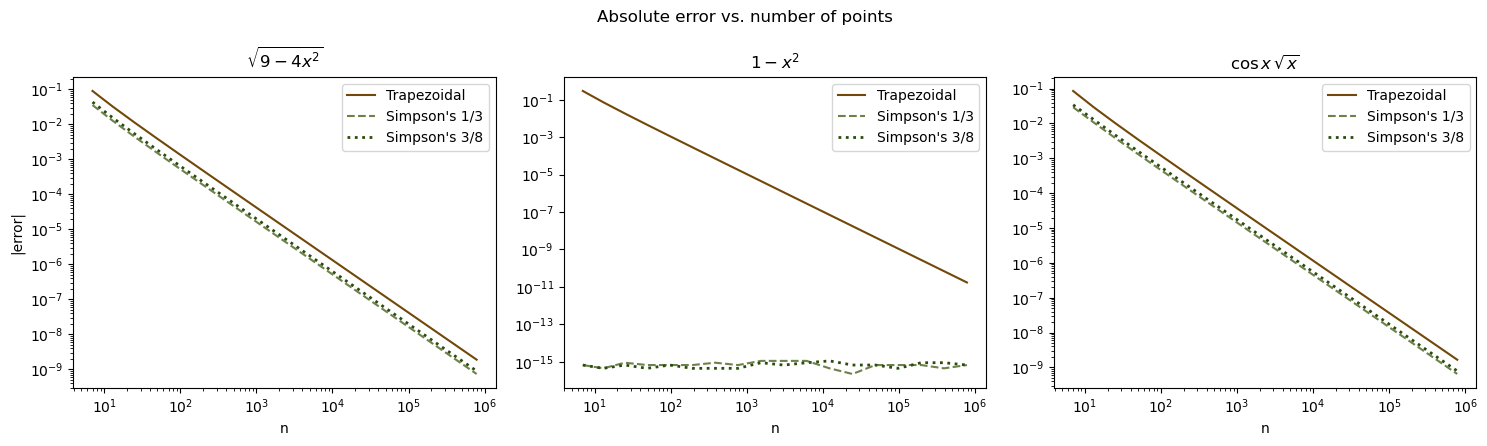

In [11]:
cases = [
    (r"$\sqrt{9-4x^2}$",    error_trapezoidal_test_a, error_simpsons13_test_a, error_simpsons38_test_a),
    (r"$1-x^2$",            error_trapezoidal_test_b, error_simpsons13_test_b, error_simpsons38_test_b),
    (r"$\cos x\,\sqrt{x}$", error_trapezoidal_test_c, error_simpsons13_test_c, error_simpsons38_test_c),
]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

for i, (name, e_trap, e_13, e_38) in enumerate(cases):
    ax[i].loglog(bins, e_trap, "-",  color="#724808", label="Trapezoidal")
    ax[i].loglog(bins, e_13,   "--", color="#6d824a", label="Simpson's 1/3")
    ax[i].loglog(bins, e_38,   ":",  color="#2b4c0c", lw=2, label="Simpson's 3/8")
    ax[i].set_title(name)
    ax[i].set_xlabel("n")
    ax[i].legend()

ax[0].set_ylabel("|error|")
fig.suptitle("Absolute error vs. number of points")
fig.tight_layout()
#fig.savefig("011_IntegrationErrorvsN.png")
plt.show()

In [12]:
# For the Monte Carlo
above_x_a, above_y_a, below_x_a, below_y_a = montecarloPlot(test_a,3/2,0,1000)
above_x_b, above_y_b, below_x_b, below_y_b = montecarloPlot(test_b,2,-2,1000)
above_x_c, above_y_c, below_x_c, below_y_c = montecarloPlot(test_c,np.pi,0,1000)

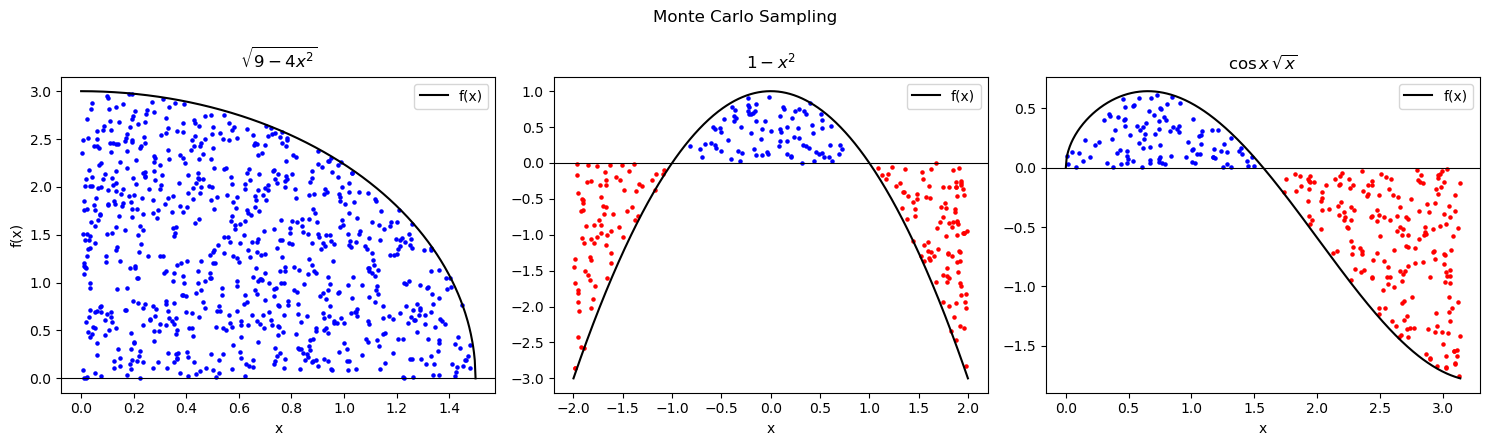

In [13]:
mc = [
    (r"$\sqrt{9-4x^2}$",    test_a, 0, 3/2,   above_x_a, above_y_a, below_x_a, below_y_a),
    (r"$1-x^2$",            test_b, -2, 2,    above_x_b, above_y_b, below_x_b, below_y_b),
    (r"$\cos x\,\sqrt{x}$", test_c, 0, np.pi, above_x_c, above_y_c, below_x_c, below_y_c),
]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

for i, (name, f, lo, hi, abx, aby, blx, bly) in enumerate(mc):
    x = np.linspace(lo, hi, 500)
    ax[i].scatter(abx, aby, s=5, c="b")
    ax[i].scatter(blx, bly, s=5, c="r")
    ax[i].plot(x, f(x), "k", label="f(x)")
    ax[i].axhline(0, color="k", lw=0.8)
    ax[i].set_title(name)
    ax[i].set_xlabel("x")
    ax[i].legend()

ax[0].set_ylabel("f(x)")
fig.suptitle("Monte Carlo Sampling")
fig.tight_layout()
#fig.savefig("011_IntegrationMonteCarlo.png")
plt.show()